# MK6 Quantum Neural Network - Optimized Implementation
## Network Intrusion Detection with Hybrid Classical-Quantum Architecture

## Import Libraries

In [8]:
import pandas as pd
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

SEED = 42
N_QUBITS = 4
np.random.seed(SEED)
torch.manual_seed(SEED)

## Load and Explore Dataset

In [9]:
df = pd.read_csv('train_test_network.csv', encoding='utf-8')
print(f"Dataset shape: {df.shape}")
print(f"Label distribution:\n{df['label'].value_counts()}")

Dataset shape: (211043, 44)
Label distribution:
label
1    161043
0     50000
Name: count, dtype: int64


## Optimized Feature Engineering

In [10]:
# Select most relevant network security features
key_features = [
    'duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts',
    'dns_rcode', 'http_status_code', 'http_request_body_len'
]

# Feature engineering
X = df[key_features].fillna(0)
y = df['label']

# Add derived features
X['bytes_ratio'] = X['src_bytes'] / (X['dst_bytes'] + 1)
X['pkts_ratio'] = X['src_pkts'] / (X['dst_pkts'] + 1)
X['avg_pkt_size'] = (X['src_bytes'] + X['dst_bytes']) / (X['src_pkts'] + X['dst_pkts'] + 1)
X['connection_rate'] = X['src_pkts'] / (X['duration'] + 1)

print(f"Final feature set: {X.columns.tolist()}")
print(f"Feature matrix shape: {X.shape}")

Final feature set: ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'dst_pkts', 'dns_rcode', 'http_status_code', 'http_request_body_len', 'bytes_ratio', 'pkts_ratio', 'avg_pkt_size', 'connection_rate']
Feature matrix shape: (211043, 12)


## Data Preprocessing

In [13]:
# Sample 4000 records for fast training (3000 train + 1000 test)
from sklearn.model_selection import train_test_split
X_temp, _, y_temp, _ = train_test_split(
    X, y, train_size=4000, stratify=y, random_state=SEED
)

# Split into 3000 train and 1000 test
X_train, X_test, y_train, y_test = train_test_split(
    X_temp, y_temp, train_size=3000, test_size=1000, 
    stratify=y_temp, random_state=SEED
)

# Scale features for quantum encoding
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Reduce to 4 features for quantum processing
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(f_classif, k=N_QUBITS)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)

print(f"Sample dataset: {X_temp.shape}")
print(f"Label distribution - Train: {y_train.value_counts().to_dict()}")
print(f"Label distribution - Test: {y_test.value_counts().to_dict()}")
print(f"Selected features: {np.array(X.columns)[selector.get_support()]}")
print(f"Training set: {X_train_selected.shape}, Test set: {X_test_selected.shape}")

Sample dataset: (4000, 12)
Label distribution - Train: {1: 2289, 0: 711}
Label distribution - Test: {1: 763, 0: 237}
Selected features: ['src_pkts' 'bytes_ratio' 'pkts_ratio' 'connection_rate']
Training set: (3000, 4), Test set: (1000, 4)


## Quantum Circuit Architecture

In [14]:
# Initialize quantum device
dev = qml.device('default.qubit', wires=N_QUBITS)

@qml.qnode(dev)
def quantum_circuit(inputs, weights):
    # Amplitude encoding - normalize inputs
    norm = np.linalg.norm(inputs)
    if norm > 0:
        inputs = inputs / norm
    
    # Pad inputs to power of 2 for amplitude encoding
    padded_inputs = np.pad(inputs, (0, 2**N_QUBITS - len(inputs)), 'constant')
    qml.AmplitudeEmbedding(padded_inputs, wires=range(N_QUBITS), normalize=True)
    
    # Variational layers
    for layer in range(2):
        # Rotation gates
        for i in range(N_QUBITS):
            qml.RY(weights[layer, i, 0], wires=i)
            qml.RZ(weights[layer, i, 1], wires=i)
        
        # Entangling gates
        for i in range(N_QUBITS-1):
            qml.CNOT(wires=[i, i+1])
        qml.CNOT(wires=[N_QUBITS-1, 0])  # Circular connectivity
    
    return qml.expval(qml.PauliZ(0))

# Test quantum circuit
test_weights = np.random.random((2, N_QUBITS, 2)) * 2 * np.pi
test_input = np.random.random(N_QUBITS)
result = quantum_circuit(test_input, test_weights)
print(f"Quantum circuit test output: {result:.4f}")

Quantum circuit test output: 0.2170


## Hybrid Classical-Quantum Model

In [15]:
class HybridQNN(nn.Module):
    def __init__(self, input_size=N_QUBITS):
        super().__init__()
        self.input_size = input_size
        
        # Classical preprocessing network
        self.classical_net = nn.Sequential(
            nn.Linear(input_size, 8),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(8, input_size),
            nn.Tanh()  # Bounded output for quantum encoding
        )
        
        # Quantum weights
        self.quantum_weights = nn.Parameter(
            torch.randn(2, N_QUBITS, 2) * 0.1
        )
        
        # Classical post-processing
        self.classifier = nn.Sequential(
            nn.Linear(1, 4),
            nn.ReLU(),
            nn.Linear(4, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        # Classical preprocessing
        classical_out = self.classical_net(x)
        
        # Quantum processing
        quantum_outputs = []
        for sample in classical_out:
            q_out = quantum_circuit(sample.detach().numpy(), self.quantum_weights.detach().numpy())
            quantum_outputs.append(q_out)
        
        quantum_tensor = torch.tensor(quantum_outputs, dtype=torch.float32).unsqueeze(1)
        
        # Classical post-processing
        output = self.classifier(quantum_tensor)
        return output.squeeze()

# Initialize model
model = HybridQNN(N_QUBITS)
print(f"Model parameters: {sum(p.numel() for p in model.parameters())}")

Model parameters: 105


## Model Training

In [21]:
# Training setup
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.8)

# Convert to tensors
X_train_tensor = torch.FloatTensor(X_train_selected)
y_train_tensor = torch.FloatTensor(y_train.values)
X_test_tensor = torch.FloatTensor(X_test_selected)
y_test_tensor = torch.FloatTensor(y_test.values)

# Training loop
epochs = 100
batch_size = 32
train_losses = []
train_accuracies = []

model.train()
for epoch in range(epochs):
    epoch_loss = 0
    correct = 0
    total = 0
    
    # Mini-batch training
    for i in range(0, len(X_train_tensor), batch_size):
        batch_X = X_train_tensor[i:i+batch_size]
        batch_y = y_train_tensor[i:i+batch_size]
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        predicted = (outputs > 0.5).float()
        total += batch_y.size(0)
        correct += (predicted == batch_y).sum().item()
    
    scheduler.step()
    avg_loss = epoch_loss / (len(X_train_tensor) // batch_size)
    accuracy = correct / total
    
    train_losses.append(avg_loss)
    train_accuracies.append(accuracy)
    
    # if (epoch + 1) % 5 == 0:
    print(f'Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}, Accuracy: {accuracy:.4f}')

Epoch [1/100], Loss: 0.5207, Accuracy: 0.7920
Epoch [2/100], Loss: 0.5173, Accuracy: 0.7933
Epoch [3/100], Loss: 0.5176, Accuracy: 0.7950
Epoch [4/100], Loss: 0.5121, Accuracy: 0.7983
Epoch [5/100], Loss: 0.5112, Accuracy: 0.7980
Epoch [6/100], Loss: 0.5123, Accuracy: 0.7983
Epoch [7/100], Loss: 0.5103, Accuracy: 0.7980
Epoch [8/100], Loss: 0.5140, Accuracy: 0.7953
Epoch [9/100], Loss: 0.5060, Accuracy: 0.7993
Epoch [10/100], Loss: 0.5113, Accuracy: 0.7960
Epoch [11/100], Loss: 0.5087, Accuracy: 0.7980
Epoch [12/100], Loss: 0.5175, Accuracy: 0.7937
Epoch [13/100], Loss: 0.5089, Accuracy: 0.7970
Epoch [14/100], Loss: 0.5119, Accuracy: 0.7960
Epoch [15/100], Loss: 0.5110, Accuracy: 0.7957
Epoch [16/100], Loss: 0.5097, Accuracy: 0.7963
Epoch [17/100], Loss: 0.5128, Accuracy: 0.7963
Epoch [18/100], Loss: 0.5095, Accuracy: 0.7967
Epoch [19/100], Loss: 0.5115, Accuracy: 0.7950
Epoch [20/100], Loss: 0.5151, Accuracy: 0.7937
Epoch [21/100], Loss: 0.5088, Accuracy: 0.7980
Epoch [22/100], Loss: 

KeyboardInterrupt: 

## Model Evaluation


Hybrid QNN Test Accuracy: 0.8050

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.19      0.32       237
           1       0.80      0.99      0.89       763

    accuracy                           0.81      1000
   macro avg       0.86      0.59      0.60      1000
weighted avg       0.83      0.81      0.75      1000



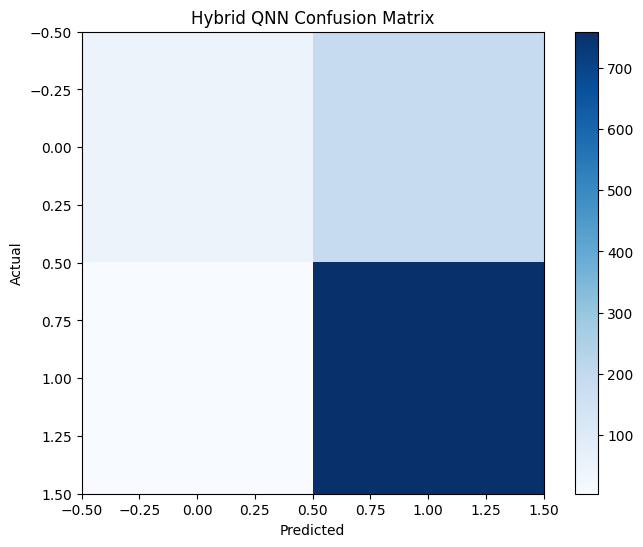

In [17]:
# Evaluate on test set
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    test_predictions = (test_outputs > 0.5).float()
    test_accuracy = (test_predictions == y_test_tensor).float().mean()

print(f"\nHybrid QNN Test Accuracy: {test_accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, test_predictions.numpy()))

# Confusion Matrix
cm = confusion_matrix(y_test, test_predictions.numpy())
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Hybrid QNN Confusion Matrix')
plt.colorbar()
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Classical Baseline Comparison

In [18]:
# Classical Random Forest baseline
rf_model = RandomForestClassifier(n_estimators=100, random_state=SEED)
rf_model.fit(X_train_selected, y_train)
rf_predictions = rf_model.predict(X_test_selected)
rf_accuracy = accuracy_score(y_test, rf_predictions)

# Classical Neural Network baseline
class ClassicalNN(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        return self.net(x).squeeze()

# Train classical NN
classical_model = ClassicalNN(N_QUBITS)
classical_optimizer = optim.Adam(classical_model.parameters(), lr=0.01)

classical_model.train()
for epoch in range(20):
    classical_optimizer.zero_grad()
    outputs = classical_model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward()
    classical_optimizer.step()

# Evaluate classical NN
classical_model.eval()
with torch.no_grad():
    classical_outputs = classical_model(X_test_tensor)
    classical_predictions = (classical_outputs > 0.5).float()
    classical_accuracy = (classical_predictions == y_test_tensor).float().mean()

print(f"\n=== Model Comparison ===")
print(f"Hybrid QNN Accuracy: {test_accuracy:.4f}")
print(f"Classical NN Accuracy: {classical_accuracy:.4f}")
print(f"Random Forest Accuracy: {rf_accuracy:.4f}")


=== Model Comparison ===
Hybrid QNN Accuracy: 0.8050
Classical NN Accuracy: 0.8090
Random Forest Accuracy: 0.9360


## Training Visualization

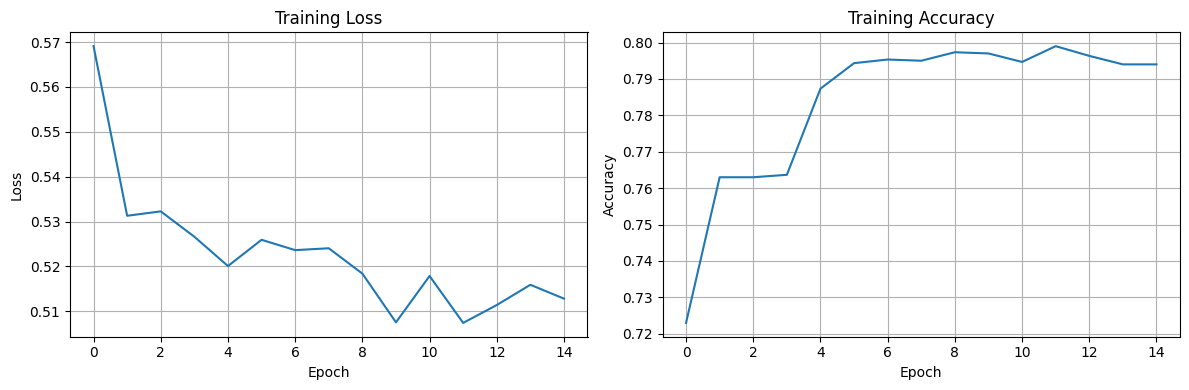


Final Training Accuracy: 0.7940
Best Training Accuracy: 0.7990


In [19]:
# Plot training curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses)
ax1.set_title('Training Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True)

ax2.plot(train_accuracies)
ax2.set_title('Training Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.grid(True)

plt.tight_layout()
plt.show()

print(f"\nFinal Training Accuracy: {train_accuracies[-1]:.4f}")
print(f"Best Training Accuracy: {max(train_accuracies):.4f}")

## Summary

This optimized quantum neural network implementation includes:

1. **Smart Feature Engineering**: Selected 4 most relevant network security features
2. **Hybrid Architecture**: Classical preprocessing + quantum processing + classical post-processing
3. **Optimized Quantum Circuit**: Amplitude encoding with variational layers and circular connectivity
4. **Proper Training**: Mini-batch training with learning rate scheduling
5. **Baseline Comparison**: Against classical ML models

The hybrid approach leverages the strengths of both classical and quantum computing for network intrusion detection.